In [1]:
import pandas as pd
import sqlalchemy
 
def sql_connection():
 
    driver = "ODBC Driver 17 for SQL Server"
    server = "VMC2VMDBRADC01P"
    database = "Analytics_Rpt"
 
    sql_string = f"mssql+pyodbc:///?odbc_connect=DRIVER={{{driver}}};SERVER={server};DATABASE={database};Trusted_Connection=yes"
    engine = sqlalchemy.create_engine(sql_string, fast_executemany=True)
 
    return engine
 
base_sql = f"""select * from Analytics_Rpt.RPT.B2BPricing_ClientMetrics_DT
                        """
engine = sql_connection()
 
df = pd.read_sql_query(base_sql, engine)

In [19]:
import os
output_path = r"C:\Users\adamakis\OneDrive - Onity Group Inc\Desktop\Projects\B2B Pricing Model\code\Python_Supervised_Unsupervised_Solutions-master\3_Unsupervised_Modeling\data\input"
file_path = os.path.join(output_path, "df_B2B.csv")
df.to_csv(file_path, index=False)

In [2]:
df.head()

,asofdt,loanid,InvestorLoanNum,Client,B2B_score,Channel,SubChannel,AmortizationTerm_Band,AmortizationType,ARMIndex_Band,...,servicing_category,servicing_subcategory,agency,investor_type,InvestorGroup,buydown_flag,buydown_type,lien_position,interest_type,occupany
0,2026-05-07,4013864394,4033664168,MILLENNIUM MORTGAGE GROUP LLC,0.506682,Correspondent,Delegated - Best Efforts,30yr,Fixed,z_Unknown,...,Owned MSR,PHH,FNMA,Fannie Mae (FNMA),Fannie Mae,0.0,None,Primary,Fixed,Primary
1,2026-05-07,4013348489,149942794,FIRST HERITAGE MORTGAGE LLC,0.816714,Correspondent,Delegated - Mandatory,30yr,Fixed,z_Unknown,...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,0.0,None,Primary,Fixed,Primary
2,2026-05-07,4013719457,151237340,MASON MCDUFFIE MORTGAGE CORPORATION,0.789725,Correspondent,Delegated - Best Efforts,30yr,Fixed,z_Unknown,...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,0.0,None,Primary,Fixed,Primary
3,2026-05-07,4013710506,151418096,OAKSTAR BANK,0.061509,Correspondent,Delegated - Best Efforts,30yr,Fixed,z_Unknown,...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,0.0,None,Primary,Fixed,Investment (Non-Owner Occupied)
4,2026-05-07,151820782,151820782,WEST PLAINS BANK & TRUST COMPANY,2.342558,Co-Issue,FHLMC CRX,30yr,Fixed,z_Unknown,...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,0.0,None,Primary,Fixed,Primary


In [3]:
exclude_cols = ["asofdt", "loanid", "InvestorLoanNum", "Client", "B2B_score"]
predictor_list = [
    col
    for col in df.columns
    if col not in exclude_cols
]
predictor_list

['Channel',
 'SubChannel',
 'AmortizationTerm_Band',
 'AmortizationType',
 'ARMIndex_Band',
 'BaseLoanAmt',
 'TotalLoanAmt',
 'CLTV',
 'DTI',
 'FICO',
 'LoanInvestor',
 'MSROwner',
 'LoanPurposeGroup',
 'LoanTypeGroup',
 'LockDuration',
 'LTV',
 'OccupancyGroup',
 'ProductCategory',
 'PropertyTypeGroup',
 'StateRegion',
 'Region',
 'PropState',
 'SelfEmployedFlag',
 'ServicingType',
 'balance_bin',
 'category',
 'origination_category',
 'servicing_category',
 'servicing_subcategory',
 'agency',
 'investor_type',
 'InvestorGroup',
 'buydown_flag',
 'buydown_type',
 'lien_position',
 'interest_type',
 'occupany']

In [4]:
categorical_columns = [
    "Channel",
    "SubChannel",
    "AmortizationTerm_Band",
    "AmortizationType",
    "ARMIndex_Band",
    "LoanInvestor",
    "MSROwner",
    "LoanPurposeGroup",
    "LoanTypeGroup",
    "SelfEmployedFlag",
    "buydown_flag",
    "OccupancyGroup",
    "ProductCategory",
    "PropertyTypeGroup",
    "StateRegion",
    "Region",
    "PropState",
    "ServicingType"
]
numeric_columns = [
    "BaseLoanAmt",
    "TotalLoanAmt",
    "CLTV",
    "DTI",
    "FICO",
    "LockDuration",
    "LTV"
]

In [5]:
def decision_tree_fun(
    df,
    target,
    predictor_list,
    tree_config,
    client_id_col=None,
    return_model=True
):
    """
    Train a leakage-safe decision tree using CART, CatBoost, or LightGBM.
    Categorical variables are handled without one-hot encoding.

    Parameters
    ----------
    df : pandas.DataFrame
        Loan-level dataset.
    target : str
        Target variable name (B2B score).
    predictor_list : dict
        {
            "categorical": [...],
            "numeric": [...]
        }
    tree_config : dict
        {
            "type": "cart" | "catboost" | "lightgbm",
            "params": { ... }
        }
    client_id_col : str, optional
        Client identifier column for sample weighting.
    return_model : bool
        Whether to return the trained model.

    Returns
    -------
    results : dict
        {
            "predictions": ndarray,
            "feature_importance": DataFrame,
            "cat_mappings": dict (col -> category labels),
            "model": object (optional)
        }
    """

    import pandas as pd
    import numpy as np

    # -----------------------------
    # Validate tree_config
    # -----------------------------
    tree_type = tree_config.get("type", "").lower()
    params = tree_config.get("params", {})

    if tree_type not in {"cart", "catboost", "lightgbm"}:
        raise ValueError("tree_config['type'] must be 'cart', 'catboost', or 'lightgbm'")

    # -----------------------------
    # Separate predictors
    # -----------------------------
    categorical_cols = predictor_list.get("categorical", [])
    numeric_cols = predictor_list.get("numeric", [])

    X = df[categorical_cols + numeric_cols].copy()
    y = df[target].copy()

    # -----------------------------
    # Drop rows where the target is NaN
    # -----------------------------
    valid_mask = y.notna()
    dropped = int((~valid_mask).sum())
    if dropped > 0:
        print(f"[decision_tree_fun] Dropping {dropped} rows with NaN in target '{target}'.")
    X = X.loc[valid_mask].reset_index(drop=True)
    y = y.loc[valid_mask].reset_index(drop=True)
    df_clean = df.loc[valid_mask].reset_index(drop=True)

    # -----------------------------
    # Optional: client-level weighting
    # -----------------------------
    sample_weight = None
    if client_id_col is not None:
        client_counts = df_clean[client_id_col].value_counts()
        sample_weight = df_clean[client_id_col].map(lambda x: 1.0 / client_counts[x])

    # =====================================================
    # CART IMPLEMENTATION
    # =====================================================
    if tree_type == "cart":

        from sklearn.tree import DecisionTreeRegressor

        # Defaults
        if params is None:
            params = {
                "max_depth": 4,
                "min_samples_leaf": 500,
                "random_state": 42
            }

        # Encode categoricals and capture mappings
        cat_mappings = {}
        for col in categorical_cols:
            cat_series = X[col].astype("category")
            cat_mappings[col] = list(cat_series.cat.categories)
            X[col] = cat_series.cat.codes

        # Cast numeric variables
        for col in numeric_cols:
            X[col] = pd.to_numeric(X[col], errors="coerce")

        # Train CART tree
        model = DecisionTreeRegressor(**params)
        model.fit(X, y, sample_weight=sample_weight)

        predictions = model.predict(X)

        feature_importance = (
            pd.DataFrame({
                "feature": X.columns,
                "importance": model.feature_importances_
            })
            .sort_values("importance", ascending=False)
            .reset_index(drop=True)
        )

        results = {
            "predictions": predictions,
            "feature_importance": feature_importance,
            "cat_mappings": cat_mappings
        }

    # =====================================================
    # CATBOOST IMPLEMENTATION (single tree)
    # =====================================================
    elif tree_type == "catboost":

        from catboost import CatBoostRegressor

        # Defaults
        if params is None:
            params = {
                "depth": 4,
                "loss_function": "RMSE",
                "iterations": 1,
                "random_seed": 42
            }

        # CatBoost cannot consume pandas NAType in categorical columns.
        # Replace missing category values with a stable string sentinel.
        for col in categorical_cols:
            X[col] = X[col].astype("object")
            X[col] = X[col].where(X[col].notna(), "__MISSING__").astype(str)

        for col in numeric_cols:
            X[col] = pd.to_numeric(X[col], errors="coerce")

        cat_features = [X.columns.get_loc(col) for col in categorical_cols]

        model = CatBoostRegressor(**params)

        model.fit(
            X,
            y,
            cat_features=cat_features,
            sample_weight=sample_weight,
            verbose=False
        )

        predictions = model.predict(X)

        feature_importance = (
            pd.DataFrame({
                "feature": X.columns,
                "importance": model.get_feature_importance()
            })
            .sort_values("importance", ascending=False)
            .reset_index(drop=True)
        )

        results = {
            "predictions": predictions,
            "feature_importance": feature_importance,
            "cat_mappings": None
        }

    # =====================================================
    # LIGHTGBM IMPLEMENTATION (single tree)
    # =====================================================
    elif tree_type == "lightgbm":

        import lightgbm as lgb

        def mean_separation_objective(y_true, y_pred):
            global_mean = y_true.mean()
            grad = -(y_true - global_mean)
            hess = np.ones_like(grad)
            return grad, hess

        if params is None:
            params = {
                "n_estimators": 1,
                "num_leaves": 16,
                "min_child_samples": 500,
                "objective": "regression",
                "random_state": 42,
                "verbosity": -1
            }
        else:
            params = dict(params)

        objective_option = str(
            params.pop("lightgbm_objective_option", params.pop("objective_option", "default"))
        ).lower()

        if objective_option in {"option_a", "a", "l1", "regression_l1", "huber"}:
            if params.get("objective") == "huber" or objective_option == "huber":
                params.setdefault("objective", "huber")
                params.setdefault("alpha", 0.9)
            else:
                params.setdefault("objective", "regression_l1")

        elif objective_option in {"option_b", "b", "quantile"}:
            params.setdefault("objective", "quantile")
            params.setdefault("alpha", 0.9)

        elif objective_option in {"option_c", "c", "mean_separation", "experimental"}:
            params["objective"] = mean_separation_objective

        elif objective_option not in {"default", "none", "current"}:
            raise ValueError(
                "lightgbm_objective_option must be one of "
                "'default', 'option_a', 'option_b', or 'option_c'"
            )

        cat_mappings = {}
        for col in categorical_cols:
            X[col] = X[col].astype("category")
            cat_mappings[col] = list(X[col].cat.categories)

        for col in numeric_cols:
            X[col] = pd.to_numeric(X[col], errors="coerce")

        model = lgb.LGBMRegressor(**params)
        model.fit(
            X,
            y,
            sample_weight=sample_weight,
            categorical_feature=categorical_cols
        )

        predictions = model.predict(X)

        booster = model.booster_
        feature_importance = (
            pd.DataFrame({
                "feature": booster.feature_name(),
                "importance_split": booster.feature_importance(importance_type="split"),
                "importance_gain": booster.feature_importance(importance_type="gain"),
            })
            .sort_values("importance_gain", ascending=False)
            .reset_index(drop=True)
        )

        results = {
            "predictions": predictions,
            "feature_importance": feature_importance,
            "cat_mappings": cat_mappings
        }

    if return_model:
        if sample_weight is not None:
            model._copilot_sample_weight = sample_weight.to_numpy(dtype=float)
        else:
            model._copilot_sample_weight = None
        model._copilot_target_name = target
        model._copilot_feature_names = list(X.columns)
        results["model"] = model

    return results


In [6]:
def visualize_decision_tree_graphviz(
    model,
    feature_names,
    max_depth=3,
    cat_mappings=None,
    data=None,
    categorical_feature_names=None,
    tree_idx=0,
    target=None
):
    """
    Graphviz visualization with human-readable category labels.

    Supported model types:
      - sklearn CART trees
      - CatBoost single trees
      - LightGBM single trees via booster_.dump_model()

    For CART, categorical split conditions like  agency <= 0.5  are replaced with
    agency in ('FHA', 'VA')  using the code-to-category mapping produced
    by decision_tree_fun.

    Visualize either a sklearn CART tree or a CatBoost single tree using Graphviz.

    For CatBoost trees the leaf nodes are enriched with:
      - the category name already shown in each split by CatBoost
      - n=<sample count>
      - avg=<mean target value>  (requires the `target` parameter)

    For LightGBM, categorical splits are reconstructed from stored category code
    lists and mapped back to readable category names using cat_mappings. Node
    sample count is based on routed rows, and node averages use the same sample
    weights as training when those weights were supplied.    
      
    Parameters
    ----------
    model : object
        Trained sklearn DecisionTreeRegressor or CatBoostRegressor.
    feature_names : list[str]
        Feature names in the same order used to train the model.
    max_depth : int
        Maximum depth to visualize for sklearn CART trees.
    cat_mappings : dict, optional
        Mapping returned by the CART training helper to replace encoded splits
        with readable category labels.
    data : pandas.DataFrame, optional
        Original feature frame. Required for CatBoost tree visualization when
        categorical features are present.
    categorical_feature_names : list[str], optional
        Names of categorical features in ``data``. Used for CatBoost Pool creation.
    tree_idx : int, default=0
        CatBoost tree index to visualize (0 for a single-tree model).
    target : str, optional
        Name of the target column in ``data``. When provided, each CatBoost
        leaf node shows the mean target value of its samples.
    """

    import html
    import os
    import re
    import subprocess
    import sys
    import numpy as np
    import pandas as pd
    from IPython.display import SVG
    from sklearn.tree import export_graphviz

    def _escape_dot_label(text):
        return str(text).replace('"', '\\"')

    def _format_categories(values, max_per_line=4):
        quoted = [f"'{str(value)}'" for value in values]
        if not quoted:
            return ["<none>"]
        return [
            ", ".join(quoted[idx: idx + max_per_line])
            for idx in range(0, len(quoted), max_per_line)
        ]

    def _build_html_label(rows):
        html_rows = []
        for row in rows:
            if isinstance(row, tuple):
                title, lines = row
                if isinstance(lines, str):
                    lines = [lines]
                escaped_lines = "<BR ALIGN=\"LEFT\"/>".join(
                    html.escape(str(line)) for line in lines
                )
                cell = f"<B>{html.escape(str(title))}</B>: {escaped_lines}"
            else:
                cell = html.escape(str(row))
            html_rows.append(f'<TR><TD ALIGN="LEFT">{cell}</TD></TR>')
        return (
            '<<TABLE BORDER="0" CELLBORDER="0" CELLPADDING="2" CELLSPACING="0">'
            + "".join(html_rows)
            + "</TABLE>>"
        )

    # ------------------------------------------------------------------
    # Locate dot.bat (conda installs the .bat wrapper, not dot.exe)
    # ------------------------------------------------------------------
    def _node_stats(mask, y_arr, weight_arr):
        count = int(mask.sum())
        if count == 0:
            return count, float("nan")
        active_weights = weight_arr[mask]
        active_y = y_arr[mask]
        weight_sum = float(active_weights.sum())
        if weight_sum > 0:
            avg_value = float(np.average(active_y, weights=active_weights))
        else:
            avg_value = float(np.mean(active_y))
        return count, avg_value

    dot_bat = os.path.join(sys.prefix, "Library", "bin", "dot.bat")
    if not os.path.exists(dot_bat):
        raise FileNotFoundError(f"Graphviz executable not found at {dot_bat}")

    # ------------------------------------------------------------------
    # Build DOT source for LightGBM, CatBoost, or sklearn CART
    # ------------------------------------------------------------------
    if hasattr(model, "booster_") and hasattr(model.booster_, "dump_model"):
        if data is None or target is None:
            raise ValueError("data and target are required to visualize LightGBM trees")

        dump = model.booster_.dump_model()
        tree_info = dump["tree_info"][tree_idx]
        tree_structure = tree_info["tree_structure"]
        lgb_feature_names = model.booster_.feature_name()
        cat_mappings = cat_mappings or {}
        categorical_feature_names = set(categorical_feature_names or [])

        valid_mask = pd.to_numeric(data[target], errors="coerce").notna().to_numpy()
        lgb_frame = data.loc[valid_mask, feature_names].copy().reset_index(drop=True)
        y_arr = pd.to_numeric(data.loc[valid_mask, target], errors="coerce").to_numpy(dtype=float)

        training_weights = getattr(model, "_copilot_sample_weight", None)
        if training_weights is not None and len(training_weights) == len(y_arr):
            weight_arr = np.asarray(training_weights, dtype=float)
        else:
            weight_arr = np.ones(len(y_arr), dtype=float)

        for col in feature_names:
            if col in categorical_feature_names:
                categories = cat_mappings.get(col)
                if categories:
                    lgb_frame[col] = pd.Categorical(lgb_frame[col], categories=categories)
                else:
                    lgb_frame[col] = lgb_frame[col].astype("category")
            else:
                lgb_frame[col] = pd.to_numeric(lgb_frame[col], errors="coerce")

        dot_lines = [
            "digraph Tree {",
            'graph [ranksep=0.45 nodesep=0.3];',
            'node [fontname="helvetica" margin="0.08,0.04"];',
            'edge [fontname="helvetica"];'
        ]
        next_node_id = 0

        def build_split_label(node, count, avg_value):
            feature_name = lgb_feature_names[node["split_feature"]]
            decision_type = node.get("decision_type")
            threshold = node.get("threshold")

            if decision_type == "==":
                left_idx = sorted(
                    {
                        int(part)
                        for part in str(threshold).split("||")
                        if str(part).strip() != ""
                    }
                )
                mapping = cat_mappings.get(feature_name, [])
                left_set = set(left_idx)
                left_categories = [
                    str(mapping[idx]) if 0 <= idx < len(mapping) else str(idx)
                    for idx in left_idx
                ]
                if mapping:
                    right_categories = [
                        str(mapping[idx])
                        for idx in range(len(mapping))
                        if idx not in left_set
                    ]
                else:
                    right_categories = ["other categories"]

                return _build_html_label([
                    f"{feature_name}",
                    ("yes", _format_categories(left_categories, max_per_line=3)),
                    ("no", _format_categories(right_categories, max_per_line=3)),
                    f"n = {count}",
                    f"avg = {avg_value:.4f}"
                ]), "Yes", "No"

            threshold_value = float(threshold)
            return _build_html_label([
                f"{feature_name} <= {threshold_value:.6g}",
                f"n = {count}",
                f"avg = {avg_value:.4f}"
            ]), "Yes", "No"

        def split_mask(node, mask):
            feature_name = lgb_feature_names[node["split_feature"]]
            decision_type = node.get("decision_type")
            threshold = node.get("threshold")
            default_left = bool(node.get("default_left", False))
            series = lgb_frame[feature_name]
            active_series = series[mask]

            if decision_type == "==":
                left_idx = {
                    int(part)
                    for part in str(threshold).split("||")
                    if str(part).strip() != ""
                }
                cat_codes = active_series.cat.codes
                cond = cat_codes.isin(left_idx).to_numpy()
                missing = (cat_codes == -1).to_numpy()
            else:
                threshold_value = float(threshold)
                numeric = pd.to_numeric(active_series, errors="coerce")
                cond = (numeric <= threshold_value).fillna(False).to_numpy()
                missing = numeric.isna().to_numpy()

            cond = np.where(missing, default_left, cond)
            active_idx = np.flatnonzero(mask)
            left_mask = np.zeros(mask.shape[0], dtype=bool)
            right_mask = np.zeros(mask.shape[0], dtype=bool)
            left_mask[active_idx[cond]] = True
            right_mask[active_idx[~cond]] = True
            return left_mask, right_mask

        def add_lgb_node(node, mask, depth=0):
            nonlocal next_node_id
            node_id = next_node_id
            next_node_id += 1

            count, avg_value = _node_stats(mask, y_arr, weight_arr)

            if "leaf_value" in node:
                label = _build_html_label([
                    "leaf",
                    f"n = {count}",
                    f"avg = {avg_value:.4f}"
                ])
                dot_lines.append(
                    f'{node_id} [label={label} shape=box style="rounded,filled" fillcolor="#f8d7da" color="#b94a48"];'
                )
                return node_id

            split_label, left_edge_label, right_edge_label = build_split_label(node, count, avg_value)
            if max_depth is not None and depth >= max_depth:
                split_label = _build_html_label([
                    "truncated",
                    f"n = {count}",
                    f"avg = {avg_value:.4f}"
                ])
                dot_lines.append(
                    f'{node_id} [label={split_label} shape=ellipse style="filled" fillcolor="#d9edf7" color="#31708f"];'
                )
                return node_id

            dot_lines.append(
                f'{node_id} [label={split_label} shape=ellipse style="filled" fillcolor="#d9edf7" color="#31708f"];'
            )

            left_mask, right_mask = split_mask(node, mask)
            left_id = add_lgb_node(node["left_child"], left_mask, depth + 1)
            right_id = add_lgb_node(node["right_child"], right_mask, depth + 1)

            dot_lines.append(f'{node_id} -> {left_id} [label="{left_edge_label}"];')
            dot_lines.append(f'{node_id} -> {right_id} [label="{right_edge_label}"];')
            return node_id

        root_mask = np.ones(len(y_arr), dtype=bool)
        add_lgb_node(tree_structure, root_mask)
        dot_lines.append("}")
        dot_data = "\n".join(dot_lines)

    elif hasattr(model, "plot_tree") and not hasattr(model, "tree_"):
        from catboost import Pool

        if data is None:
            raise ValueError("data is required to visualize CatBoost trees")

        categorical_feature_names = categorical_feature_names or []
        cat_feature_frame = data[feature_names].copy()

        for col in categorical_feature_names:
            if col in cat_feature_frame.columns:
                cat_feature_frame[col] = cat_feature_frame[col].astype("object")
                cat_feature_frame[col] = (
                    cat_feature_frame[col]
                    .where(cat_feature_frame[col].notna(), "__MISSING__")
                    .astype(str)
                )

        for col in feature_names:
            if col not in categorical_feature_names:
                import pandas as _pd
                cat_feature_frame[col] = _pd.to_numeric(
                    cat_feature_frame[col], errors="coerce"
                )

        cat_features = [
            cat_feature_frame.columns.get_loc(col)
            for col in categorical_feature_names
            if col in cat_feature_frame.columns
        ]
        pool = Pool(cat_feature_frame, cat_features=cat_features)

        # Get the DOT source from CatBoost (already contains category split names)
        dot_data = model.plot_tree(tree_idx, pool).source

        # ------------------------------------------------------------------
        # Enrich leaf nodes: add sample count and mean target
        # ------------------------------------------------------------------
        depth = model.get_params().get("depth", 6)
        n_leaves = 2 ** depth
        first_leaf_dot_id = n_leaves - 1   # CatBoost oblivious trees are full binary trees

        leaf_indexes = model.calc_leaf_indexes(pool)[:, 0]   # (n_samples,) 0-based leaf idx
        y_arr = data[target].values if target is not None else None

        leaf_stats = {}
        for leaf_idx in range(n_leaves):
            mask = leaf_indexes == leaf_idx
            cnt = int(mask.sum())
            mean_t = float(np.mean(y_arr[mask])) if (y_arr is not None and cnt > 0) else None
            leaf_stats[first_leaf_dot_id + leaf_idx] = (cnt, mean_t)

        def enrich_leaf_label(match):
            node_id = int(match.group(1))
            old_label = match.group(2)
            if node_id not in leaf_stats:
                return match.group(0)
            cnt, mean_t = leaf_stats[node_id]
            # CatBoost labels end with a literal newline; keep it, just append new lines before it
            clean = old_label.rstrip("\n")
            extra = f"\nn = {cnt}"
            if mean_t is not None:
                extra += f"\navg = {mean_t:.4f}"
            return f'{node_id} [label="{clean}{extra}\n" color=red shape=rect]'

        dot_data = re.sub(
            r'(\d+) \[label="(.*?)" color=red shape=rect\]',
            enrich_leaf_label,
            dot_data,
            flags=re.DOTALL
        )

    else:
        dot_data = export_graphviz(
            model,
            feature_names=feature_names,
            filled=True,
            rounded=True,
            max_depth=max_depth,
            impurity=False
        )

        # --------------------------------------------------------------
        # Replace encoded CART thresholds with readable category labels
        # --------------------------------------------------------------
        if cat_mappings:
            def replace_condition(match):
                feature = match.group(1)
                threshold = float(match.group(2))
                if feature not in cat_mappings:
                    return match.group(0)

                categories = cat_mappings[feature]
                cut = int(threshold)
                left_cats = [
                    str(categories[i])
                    for i in range(min(cut + 1, len(categories)))
                ]

                max_show = 5
                if len(left_cats) <= max_show:
                    cats_str = ", ".join(f"'{category}'" for category in left_cats)
                else:
                    cats_str = (
                        ", ".join(f"'{category}'" for category in left_cats[:max_show])
                        + ", ..."
                    )
                return f"{feature} in ({cats_str})"

            dot_data = re.sub(r"([\w]+) <= ([\d.]+)", replace_condition, dot_data)

    # ------------------------------------------------------------------
    # Render via dot.bat and return as inline SVG
    # ------------------------------------------------------------------
    process = subprocess.run(
        ["cmd", "/c", dot_bat, "-Tsvg"],
        input=dot_data,
        text=True,
        capture_output=True,
        check=True
    )

    return SVG(process.stdout)


In [7]:
def cart_tree_to_dict(model, feature_names, cat_mappings=None):
    """
    Serialize a sklearn DecisionTreeRegressor to a JSON-compatible dict.
    Categorical split conditions are expanded to readable category lists
    when cat_mappings is provided.
    """
    tree = model.tree_
    n_nodes = tree.node_count
    children_left  = tree.children_left.tolist()
    children_right = tree.children_right.tolist()
    feature_idx    = tree.feature.tolist()
    threshold      = tree.threshold.tolist()
    n_samples      = tree.n_node_samples.tolist()
    values         = tree.value.tolist()   # shape (n_nodes, 1, 1) for regression

    LEAF = -1   # sklearn sentinel for leaf nodes

    def node_to_dict(node_id):
        is_leaf = children_left[node_id] == LEAF

        mean_value = float(values[node_id][0][0])
        count      = int(n_samples[node_id])

        if is_leaf:
            return {
                "node_type": "leaf",
                "n_samples": count,
                "value": round(mean_value, 6)
            }

        feat_name  = feature_names[feature_idx[node_id]]
        thresh_val = threshold[node_id]

        if cat_mappings and feat_name in cat_mappings:
            cats = cat_mappings[feat_name]
            cut  = int(thresh_val)
            left_cats  = [str(cats[i]) for i in range(min(cut + 1, len(cats)))]
            right_cats = [str(cats[i]) for i in range(cut + 1, len(cats))]
            split_condition = {
                "feature": feat_name,
                "type": "categorical",
                "left_categories":  left_cats,
                "right_categories": right_cats
            }
        else:
            split_condition = {
                "feature": feat_name,
                "type": "numeric",
                "threshold": round(thresh_val, 6)
            }

        return {
            "node_type": "split",
            "n_samples": count,
            "value": round(mean_value, 6),
            "split": split_condition,
            "left":  node_to_dict(children_left[node_id]),
            "right": node_to_dict(children_right[node_id])
        }

    return {
        "model_type": "DecisionTreeRegressor",
        "params": model.get_params(),
        "feature_names": list(feature_names),
        "tree": node_to_dict(0)
    }

In [8]:
def save_model_json(dt_results, save_dir, feature_names=None):
    """
    Save a trained model to JSON in save_dir.

    The filename is derived from the model type:
        cart_model.json       (sklearn DecisionTreeRegressor)
        catboost_model.json   (CatBoostRegressor)
        lightgbm_model.json   (LGBMRegressor)

    Parameters
    ----------
    dt_results : dict
        Dict returned by decision_tree_fun (must contain "model" and "cat_mappings").
    save_dir : str
        Directory where the file will be written.
    feature_names : list[str], optional
        Required for CART models to produce readable node labels in the JSON.
    """
    import os
    import json

    model = dt_results["model"]
    cat_mappings = dt_results.get("cat_mappings")
    model_class = type(model).__name__

    if model_class == "DecisionTreeRegressor":
        filename = "cart_model.json"
        save_path = os.path.join(save_dir, filename)
        data = cart_tree_to_dict(
            model=model,
            feature_names=feature_names or [],
            cat_mappings=cat_mappings
        )
        with open(save_path, "w", encoding="utf-8") as f:
            json.dump(data, f, indent=2)

    elif model_class == "CatBoostRegressor":
        filename = "catboost_model.json"
        save_path = os.path.join(save_dir, filename)
        model.save_model(save_path, format="json")

    elif model_class == "LGBMRegressor":
        filename = "lightgbm_model.json"
        save_path = os.path.join(save_dir, filename)
        dump = model.booster_.dump_model()
        with open(save_path, "w", encoding="utf-8") as f:
            json.dump(dump, f, indent=2)

    else:
        raise ValueError(f"Unsupported model type: {model_class}")

    print(f"Model saved to: {save_path}")
    return save_path


In [ ]:
import pandas as pd
import numpy as np

def group_categories_by_target(
    df,
    col,
    target,
    n_groups=4,
    weight_col=None,
    min_weight=None
):
    """
    Group categories by (weighted) target signal.
    Group labels are tuples of category names, e.g. ('TX','NY').

    Returns
    -------
    mapping : dict
        category -> tuple of categories in its group
    stats : DataFrame
        per-category statistics and group assignment
    """

    # -----------------------------
    # Compute (weighted) mean target per category
    # -----------------------------
    if weight_col is None:
        stats = (
            df.groupby(col)[target]
              .mean()
              .reset_index(name="mean_target")
        )
        stats["total_weight"] = df.groupby(col).size().values
    else:
        stats = (
            df
            .groupby(col)
            .apply(lambda g: np.average(g[target], weights=g[weight_col]))
            .reset_index(name="mean_target")
        )
        stats["total_weight"] = df.groupby(col)[weight_col].sum().values

    # -----------------------------
    # Apply min_weight filter
    # -----------------------------
    if min_weight is not None:
        stats = stats[stats["total_weight"] >= min_weight].copy()

    # -----------------------------
    # Sort categories by signal
    # -----------------------------
    stats = stats.sort_values("mean_target").reset_index(drop=True)

    # -----------------------------
    # Assign quantile-based group IDs
    # -----------------------------
    stats["group_id"] = pd.qcut(
        stats["mean_target"],
        q=n_groups,
        labels=False,
        duplicates="drop"
    )

    # -----------------------------
    # Keep only rows with valid group_id
    # -----------------------------
    stats_valid = stats[stats["group_id"].notna()].copy()

    # -----------------------------
    # Build group_id -> tuple(categories)
    # -----------------------------
    group_to_categories = (
        stats_valid
        .groupby("group_id")[col]
        .apply(lambda x: tuple(sorted(x)))
        .to_dict()
    )

    # -----------------------------
    # FINAL mapping: category -> tuple label
    # -----------------------------
    mapping = {
        row[col]: group_to_categories[row["group_id"]]
        for _, row in stats_valid.iterrows()
    }

    return mapping, stats


In [10]:
def recode_categorical_columns_by_target(
    df,
    col_list,
    target,
    n_groups=4,
    weight_col=None,
    min_weight=None
):
    """
    Recode selected categorical columns using target-driven grouping.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataframe.
    col_list : list[str]
        List of column names to be recoded.
        ONLY these columns will be recoded.
    target : str
        Target variable name.
    n_groups : int, default=4
        Maximum number of groups per categorical variable.
    weight_col : str, optional
        Sampling weight column.
    min_weight : float, optional
        Minimum total weight per category.

    Returns
    -------
    df_recoded : pandas.DataFrame
        DataFrame with specified columns replaced by recoded versions.
    mappings : dict
        Dictionary of mappings per column:
        {
            col_name: category -> tuple_label
        }
    stats_all : dict
        Per-column stats DataFrames.
    """

    df_recoded = df.copy()
    mappings = {}
    stats_all = {}

    for col in col_list:

        mapping, stats = group_categories_by_target(
            df=df_recoded,
            col=col,
            target=target,
            n_groups=n_groups,
            weight_col=weight_col,
            min_weight=min_weight
        )

        # FIX: handle tuple-valued fill correctly
        mapped = df_recoded[col].map(mapping)
        df_recoded[col] = mapped.apply(
            lambda x: x if pd.notna(x) else ("Other",)
        )

        mappings[col] = mapping
        stats_all[col] = stats

    return df_recoded, mappings, stats_all



In [11]:
df_recoded, mappings, stats_all = recode_categorical_columns_by_target(
    df=df,
    col_list=categorical_columns,
    target="B2B_score",
    n_groups=3,
    weight_col=None,
    min_weight=1000
)
df_recoded.head()

,asofdt,loanid,InvestorLoanNum,Client,B2B_score,Channel,SubChannel,AmortizationTerm_Band,AmortizationType,ARMIndex_Band,...,servicing_category,servicing_subcategory,agency,investor_type,InvestorGroup,buydown_flag,buydown_type,lien_position,interest_type,occupany
0,2026-05-07,4013864394,4033664168,MILLENNIUM MORTGAGE GROUP LLC,0.506682,"(Correspondent,)","(Delegated - Best Efforts, FHLMC CRX, Non-dele...","(30yr,)","(Other,)","(Other,)",...,Owned MSR,PHH,FNMA,Fannie Mae (FNMA),Fannie Mae,"(0.0,)",None,Primary,Fixed,Primary
1,2026-05-07,4013348489,149942794,FIRST HERITAGE MORTGAGE LLC,0.816714,"(Correspondent,)","(Delegated - Mandatory, FNMA SMP)","(30yr,)","(Other,)","(Other,)",...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,"(0.0,)",None,Primary,Fixed,Primary
2,2026-05-07,4013719457,151237340,MASON MCDUFFIE MORTGAGE CORPORATION,0.789725,"(Correspondent,)","(Delegated - Best Efforts, FHLMC CRX, Non-dele...","(30yr,)","(Other,)","(Other,)",...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,"(0.0,)",None,Primary,Fixed,Primary
3,2026-05-07,4013710506,151418096,OAKSTAR BANK,0.061509,"(Correspondent,)","(Delegated - Best Efforts, FHLMC CRX, Non-dele...","(30yr,)","(Other,)","(Other,)",...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,"(0.0,)",None,Primary,Fixed,Investment (Non-Owner Occupied)
4,2026-05-07,151820782,151820782,WEST PLAINS BANK & TRUST COMPANY,2.342558,"(Co-Issue,)","(Delegated - Best Efforts, FHLMC CRX, Non-dele...","(30yr,)","(Other,)","(Other,)",...,NaN,NaN,FHLMC,Freddie Mac (FHLMC),Freddie Mac,"(0.0,)",None,Primary,Fixed,Primary


In [12]:
dt_results = decision_tree_fun(
    df=df,
#    df=df_recoded,
    target="B2B_score",
    predictor_list={"categorical": categorical_columns, "numeric": numeric_columns},
     tree_config={"type": "cart", "params": {"max_depth": 4, "min_samples_leaf": 500, "random_state": 42}},
#    tree_config={"type": "catboost", "params": {"depth": 3, "iterations": 1, "min_data_in_leaf": 1000, "loss_function": "RMSE", "random_seed": 42}},
#    tree_config={"type": "lightgbm", "params": {"n_estimators": 1, "max_depth": 4, "num_leaves": 16, "min_child_samples": 1000, "max_cat_threshold": 16, "cat_smooth": 20, "lambda_l2": 5, "min_split_gain": 0.0, "verbose":-1}},
#    tree_config={"type": "lightgbm", "params": {"n_estimators": 1, "max_depth": 4, "num_leaves": 16, "min_child_samples": 200, "max_cat_threshold": 32, "cat_smooth": 1, "lambda_l2": 0, "min_split_gain": 0.0, "verbose":-1}},
#    tree_config={"type": "lightgbm", "params": {"n_estimators": 1, "max_depth": 4, "num_leaves": 16, "min_child_samples": 50, "max_cat_threshold": 32, "cat_smooth": 0, "lambda_l2": 0, "min_split_gain": 0.0, "verbose":-1}},
#    tree_config={"type": "lightgbm", "params": {"n_estimators": 1, "max_depth": 4, "num_leaves": 16, "min_child_samples": 1000, "max_cat_threshold": 32, "cat_smooth": 0, "lambda_l2": 0, "min_split_gain": 0.0, "verbose":-1, "lightgbm_objective_option": "option_a"}},
    client_id_col="Client",
    return_model=True
)

dt_results

{'predictions': array([1.12514355, 1.07430118, 1.12514355, ..., 1.12514355, 1.11990294,
        1.11990294], shape=(119591,)),
 'feature_importance':                   feature  importance
 0               PropState    0.416313
 1             StateRegion    0.312763
 2              SubChannel    0.145097
 3        SelfEmployedFlag    0.090961
 4                    FICO    0.019547
 5                  Region    0.007729
 6            LockDuration    0.007590
 7                 Channel    0.000000
 8   AmortizationTerm_Band    0.000000
 9           LoanTypeGroup    0.000000
 10       LoanPurposeGroup    0.000000
 11               MSROwner    0.000000
 12           LoanInvestor    0.000000
 13          ARMIndex_Band    0.000000
 14       AmortizationType    0.000000
 15        ProductCategory    0.000000
 16         OccupancyGroup    0.000000
 17      PropertyTypeGroup    0.000000
 18           buydown_flag    0.000000
 19          ServicingType    0.000000
 20            BaseLoanAmt    0.

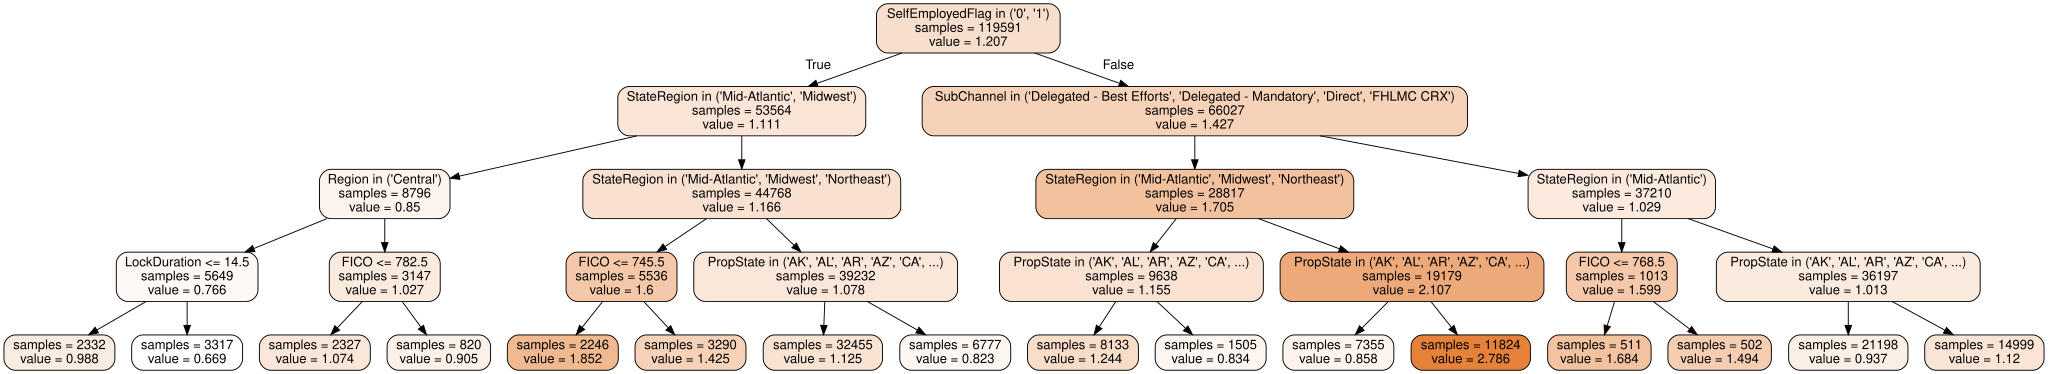

In [13]:
visualize_decision_tree_graphviz(
    model=dt_results["model"],
    feature_names=(
        categorical_columns
        + numeric_columns
    ),
    max_depth=4,
    cat_mappings=dt_results["cat_mappings"],
    data=df,
    categorical_feature_names=categorical_columns,
    tree_idx=0,
    target="B2B_score"
)


In [14]:
save_model_json(
    dt_results=dt_results,
    save_dir=r"C:\Users\adamakis\OneDrive - Onity Group Inc\GitHub repos\B2B-Pricing-Model\B2B-Pricing-Model\repo\python",
    feature_names=categorical_columns + numeric_columns
)

Model saved to: C:\Users\adamakis\OneDrive - Onity Group Inc\GitHub repos\B2B-Pricing-Model\B2B-Pricing-Model\repo\python\cart_model.json


'C:\\Users\\adamakis\\OneDrive - Onity Group Inc\\GitHub repos\\B2B-Pricing-Model\\B2B-Pricing-Model\\repo\\python\\cart_model.json'